# Proyek Analisis Data: Bike Sharing Dataset

- **Nama:** [Isi nama]
- **Email:** [Isi email]
- **ID Dicoding:** [Isi username Dicoding]

**Cakupan analisis:** pola penyewaan sepeda berdasarkan jam, jenis hari, musim, dan kondisi cuaca pada sistem Capital Bikeshare di Washington, D.C. selama 2011–2012.

> **Petunjuk penggunaan:** letakkan file `day.csv` dan `hour.csv` pada direktori yang sama dengan notebook (di Google Colab, unggah keduanya ke panel Files). Jalankan seluruh cell dari atas ke bawah.

## Menentukan Pertanyaan Bisnis

Analisis ini berfokus pada kebutuhan operasional pengelola layanan bike sharing, khususnya perencanaan ketersediaan dan redistribusi armada.

### Pertanyaan 1 — Pola permintaan per jam

**Bagaimana pola rata-rata jumlah penyewaan sepeda per jam berbeda antara hari kerja dan hari bukan kerja di Washington, D.C. selama 1 Januari 2011–31 Desember 2012, dan pada jam berapa permintaan mencapai puncaknya?**

- **Specific:** membandingkan pola penyewaan per jam antara hari kerja dan hari bukan kerja.
- **Measurable:** menggunakan rata-rata jumlah penyewaan (`cnt`) untuk setiap jam (0–23).
- **Action-oriented:** hasilnya dapat digunakan untuk menentukan waktu redistribusi dan penempatan sepeda.
- **Relevant:** ketersediaan armada pada jam dengan permintaan tinggi berhubungan langsung dengan kualitas layanan.
- **Time-bound:** periode 1 Januari 2011–31 Desember 2012.

### Pertanyaan 2 — Pola permintaan menurut musim dan cuaca

**Bagaimana rata-rata jumlah penyewaan sepeda harian berbeda menurut musim dan kondisi cuaca di Washington, D.C. selama 1 Januari 2011–31 Desember 2012, dan kombinasi musim–cuaca mana yang menunjukkan permintaan tertinggi serta terendah?**

- **Specific:** mengevaluasi jumlah penyewaan harian menurut musim dan kondisi cuaca.
- **Measurable:** menggunakan rata-rata jumlah penyewaan harian (`cnt`) dan jumlah hari pada setiap kelompok.
- **Action-oriented:** hasilnya dapat mendukung perencanaan kapasitas armada dan antisipasi penurunan permintaan.
- **Relevant:** musim dan cuaca merupakan faktor lingkungan yang berkaitan dengan perilaku penyewaan.
- **Time-bound:** periode 1 Januari 2011–31 Desember 2012.

## Import Semua Packages/Library yang Digunakan

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

## Data Wrangling

### Gathering Data

Dataset Bike Sharing terdiri dari dua file dengan tingkat agregasi berbeda:
- `day.csv`: satu baris untuk setiap tanggal.
- `hour.csv`: satu baris untuk setiap jam.

Keduanya berasal dari periode dan sistem penyewaan yang sama. Keduanya digunakan untuk analisis yang berbeda dan **tidak dijumlahkan**, agar tidak terjadi penghitungan ganda.

#### Load `day.csv` dan `hour.csv`

In [2]:
DATA_DIR = Path(".")
DAY_PATH = DATA_DIR / "day.csv"
HOUR_PATH = DATA_DIR / "hour.csv"

if not DAY_PATH.exists() or not HOUR_PATH.exists():
    raise FileNotFoundError(
        "File day.csv dan hour.csv harus berada di direktori kerja notebook. "
        "Di Google Colab, unggah kedua file melalui panel Files, lalu jalankan ulang cell ini."
    )

day_df = pd.read_csv(DAY_PATH)
hour_df = pd.read_csv(HOUR_PATH)

print(f"day.csv  : {day_df.shape[0]:,} baris × {day_df.shape[1]} kolom")
print(f"hour.csv : {hour_df.shape[0]:,} baris × {hour_df.shape[1]} kolom")
print("\nContoh day.csv:")
display(day_df.head())
print("Contoh hour.csv:")
display(hour_df.head())

day.csv  : 731 baris × 16 kolom
hour.csv : 17,379 baris × 17 kolom

Contoh day.csv:


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.34,0.36,0.81,0.16,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.36,0.35,0.70,0.25,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.20,0.19,0.44,0.25,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.20,0.21,0.59,0.16,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.23,0.23,0.44,0.19,82,1518,1600


Contoh hour.csv:


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.29,0.81,0.00,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.27,0.80,0.00,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.27,0.80,0.00,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.29,0.75,0.00,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.29,0.75,0.00,0,1,1


**Insight Gathering Data:**
- `day.csv` berisi 731 observasi harian dan 16 kolom.
- `hour.csv` berisi 17.379 observasi per jam dan 17 kolom.
- Kedua file mencakup 1 Januari 2011 sampai 31 Desember 2012. Kolom `hr` hanya tersedia pada `hour.csv`.
- Variabel target jumlah penyewaan adalah `cnt`, yang merupakan penjumlahan pengguna kasual (`casual`) dan terdaftar (`registered`).

### Assessing Data

Pemeriksaan kualitas dilakukan terhadap kelengkapan, duplikasi, konsistensi nilai, rentang kategori, kelengkapan kombinasi tanggal–jam, serta potensi pencilan pada jumlah penyewaan.

#### 1. Memeriksa missing value dan duplicate data

In [3]:
missing_summary = pd.DataFrame({
    "day_missing": day_df.isna().sum(),
    "hour_missing": hour_df.isna().sum()
}).fillna(0).astype(int)

duplicate_summary = pd.DataFrame({
    "Dataset": ["day.csv", "hour.csv"],
    "Duplicate seluruh baris": [day_df.duplicated().sum(), hour_df.duplicated().sum()],
    "Duplicate tanggal-jam": [np.nan, hour_df.duplicated(subset=["dteday", "hr"]).sum()]
})

print("Missing value per kolom:")
display(missing_summary)
print("Pemeriksaan duplikasi:")
display(duplicate_summary)

Missing value per kolom:


,day_missing,hour_missing
atemp,0,0
casual,0,0
cnt,0,0
dteday,0,0
holiday,0,0
hr,0,0
hum,0,0
instant,0,0
mnth,0,0
registered,0,0


Pemeriksaan duplikasi:


,Dataset,Duplicate seluruh baris,Duplicate tanggal-jam
0,day.csv,0,NaN
1,hour.csv,0,0.00


#### 2. Memeriksa konsistensi dan nilai kategori

In [4]:
# Identitas jumlah penyewaan: total harus sama dengan casual + registered.
consistency_summary = pd.DataFrame({
    "Dataset": ["day.csv", "hour.csv"],
    "Mismatch cnt != casual + registered": [
        (day_df["cnt"] != day_df["casual"] + day_df["registered"]).sum(),
        (hour_df["cnt"] != hour_df["casual"] + hour_df["registered"]).sum()
    ]
})

allowed_categories = {
    "season": {1, 2, 3, 4},
    "yr": {0, 1},
    "mnth": set(range(1, 13)),
    "holiday": {0, 1},
    "weekday": set(range(0, 7)),
    "workingday": {0, 1},
    "weathersit": {1, 2, 3, 4}
}
invalid_rows = []
for dataset_name, frame in [("day.csv", day_df), ("hour.csv", hour_df)]:
    for column, allowed in allowed_categories.items():
        invalid_count = (~frame[column].isin(allowed)).sum()
        invalid_rows.append({"Dataset": dataset_name, "Kolom": column, "Invalid value": int(invalid_count)})

print("Pemeriksaan konsistensi jumlah penyewaan:")
display(consistency_summary)
print("Pemeriksaan nilai kategori di luar kode yang diizinkan:")
display(pd.DataFrame(invalid_rows).pivot(index="Kolom", columns="Dataset", values="Invalid value"))

Pemeriksaan konsistensi jumlah penyewaan:


,Dataset,Mismatch cnt != casual + registered
0,day.csv,0
1,hour.csv,0


Pemeriksaan nilai kategori di luar kode yang diizinkan:


Dataset,day.csv,hour.csv
Kolom,,
holiday,0,0
mnth,0,0
season,0,0
weathersit,0,0
weekday,0,0
workingday,0,0
yr,0,0


#### 3. Memeriksa kelengkapan tanggal dan jam

Karena data per jam seharusnya memiliki 24 catatan untuk setiap tanggal, jumlah kombinasi tanggal–jam aktual dibandingkan dengan 24 jam yang diharapkan.

In [5]:
hour_dates = pd.to_datetime(hour_df["dteday"], errors="coerce")
unique_hours_per_date = hour_df.assign(dteday=hour_dates).groupby("dteday")["hr"].nunique()
expected_hourly_rows = hour_dates.nunique() * 24
observed_hourly_rows = len(hour_df)
incomplete_dates = unique_hours_per_date[unique_hours_per_date != 24]
complete_dates = unique_hours_per_date[unique_hours_per_date == 24].index

hour_completeness = pd.DataFrame({
    "Keterangan": [
        "Jumlah tanggal pada hour.csv",
        "Jumlah baris aktual",
        "Jumlah baris yang diharapkan (24 jam × tanggal)",
        "Kombinasi tanggal-jam yang tidak tercatat",
        "Tanggal dengan 24 jam lengkap",
        "Tanggal dengan jam tidak lengkap"
    ],
    "Nilai": [
        hour_dates.nunique(), observed_hourly_rows, expected_hourly_rows,
        expected_hourly_rows - observed_hourly_rows,
        len(complete_dates), len(incomplete_dates)
    ]
})
display(hour_completeness)

,Keterangan,Nilai
0,Jumlah tanggal pada hour.csv,731
1,Jumlah baris aktual,17379
2,Jumlah baris yang diharapkan (24 jam × tanggal),17544
3,Kombinasi tanggal-jam yang tidak tercatat,165
4,Tanggal dengan 24 jam lengkap,655
5,Tanggal dengan jam tidak lengkap,76


#### 4. Mengidentifikasi potential outlier dengan metode IQR

In [6]:
def iqr_outlier_summary(data, column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (data[column] < lower) | (data[column] > upper)
    return {
        "Q1": q1, "Q3": q3, "IQR": iqr,
        "Batas bawah": lower, "Batas atas": upper,
        "Jumlah potential outlier": int(mask.sum()),
        "Persentase (%)": mask.mean() * 100
    }

outlier_summary = pd.DataFrame({
    "day.csv (cnt)": iqr_outlier_summary(day_df, "cnt"),
    "hour.csv (cnt)": iqr_outlier_summary(hour_df, "cnt")
}).T
display(outlier_summary)

,Q1,Q3,IQR,Batas bawah,Batas atas,Jumlah potential outlier,Persentase (%)
day.csv (cnt),"3,152.00","5,956.00","2,804.00","-1,054.00","10,162.00",0.00,0.00
hour.csv (cnt),40.00,281.00,241.00,-321.50,642.50,505.00,2.91


### Rencana Tindakan pada Tahap Cleaning Data

Temuan dan keputusan penanganan:

1. **Kelengkapan data per jam:** tidak ditemukan sel `NaN`, tetapi terdapat 165 kombinasi tanggal–jam yang tidak tercatat pada 76 tanggal. Untuk analisis profil rata-rata per jam, gunakan hanya tanggal dengan 24 observasi. Jam yang hilang tidak diisi nol karena ketiadaan catatan tidak otomatis berarti tidak ada penyewaan.
2. **Potential outlier pada `hour.csv`:** 505 observasi melewati batas IQR (batas atas 642,5). Nilai ini tidak langsung dihapus karena lonjakan permintaan dapat merupakan kejadian nyata. Tandai sebagai potential outlier dan pertahankan agar pola permintaan puncak tidak hilang.
3. **Missing value, duplikasi, konsistensi `cnt`, dan kode kategori:** hasil pemeriksaan menunjukkan tidak ada masalah pada aspek-aspek tersebut. Tidak diperlukan penghapusan atau imputasi untuk pemeriksaan ini.
4. **Format tanggal dan label kategori:** ubah `dteday` menjadi tipe datetime dan tambahkan label yang mudah dibaca untuk musim, cuaca, dan jenis hari.

### Cleaning Data

Pembersihan dilakukan berdasarkan hasil penilaian data. Data sumber tetap dipertahankan, sedangkan tabel bersih dibuat sebagai salinan agar keputusan pengolahan dapat ditelusuri.

#### Membersihkan format, label, dan kelengkapan data hourly

In [7]:
# Salin data sumber dan ubah tanggal ke format datetime.
day_clean = day_df.copy()
hour_clean_all = hour_df.copy()

day_clean["dteday"] = pd.to_datetime(day_clean["dteday"], errors="coerce")
hour_clean_all["dteday"] = pd.to_datetime(hour_clean_all["dteday"], errors="coerce")

season_map = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
weather_map = {
    1: "Clear",
    2: "Misty / Cloudy",
    3: "Light Rain / Snow",
    4: "Heavy Rain / Snow"
}

def add_readable_labels(frame):
    result = frame.copy()
    result["season_label"] = result["season"].map(season_map)
    result["weather_label"] = result["weathersit"].map(weather_map)
    result["day_type"] = np.where(result["workingday"].eq(1), "Working day", "Non-working day")
    result["year_label"] = result["yr"].map({0: 2011, 1: 2012})
    return result

day_clean = add_readable_labels(day_clean)
hour_clean_all = add_readable_labels(hour_clean_all)

# Ambil tanggal dengan catatan tepat 24 jam untuk analisis profil per jam.
hours_per_day = hour_clean_all.groupby("dteday")["hr"].nunique()
complete_hour_dates = hours_per_day[hours_per_day.eq(24)].index
hour_clean = hour_clean_all[hour_clean_all["dteday"].isin(complete_hour_dates)].copy()

# Tandai potential outlier (bukan menghapusnya).
q1_hour = hour_clean_all["cnt"].quantile(0.25)
q3_hour = hour_clean_all["cnt"].quantile(0.75)
iqr_hour = q3_hour - q1_hour
upper_hour = q3_hour + 1.5 * iqr_hour
hour_clean["potential_outlier_cnt"] = hour_clean["cnt"] > upper_hour

print(f"day_clean       : {day_clean.shape}")
print(f"hour_clean_all  : {hour_clean_all.shape}")
print(f"hour_clean      : {hour_clean.shape} (hanya tanggal dengan 24 jam lengkap)")
print(f"Potential outlier pada hour_clean yang dipertahankan: {hour_clean['potential_outlier_cnt'].sum():,}")
display(day_clean.head(3))
display(hour_clean.head(3))

day_clean       : (731, 20)
hour_clean_all  : (17379, 21)
hour_clean      : (15720, 22) (hanya tanggal dengan 24 jam lengkap)
Potential outlier pada hour_clean yang dipertahankan: 502


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,season_label,weather_label,day_type,year_label
0,1,2011-01-01,1,0,1,0,6,0,2,0.34,0.36,0.81,0.16,331,654,985,Spring,Misty / Cloudy,Non-working day,2011
1,2,2011-01-02,1,0,1,0,0,0,2,0.36,0.35,0.70,0.25,131,670,801,Spring,Misty / Cloudy,Non-working day,2011
2,3,2011-01-03,1,0,1,0,1,1,1,0.20,0.19,0.44,0.25,120,1229,1349,Spring,Clear,Working day,2011


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,season_label,weather_label,day_type,year_label,potential_outlier_cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.29,0.81,0.00,3,13,16,Spring,Clear,Non-working day,2011,False
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.27,0.80,0.00,8,32,40,Spring,Clear,Non-working day,2011,False
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.27,0.80,0.00,5,27,32,Spring,Clear,Non-working day,2011,False


**Validasi hasil cleaning:**
- Data harian tetap memiliki 731 observasi.
- Data per jam untuk analisis pola lengkap terdiri dari 15.720 observasi atau 655 tanggal × 24 jam.
- Tidak ada imputasi nol pada jam yang tidak tercatat.
- Potential outlier tetap dipertahankan dan diberi penanda agar lonjakan permintaan yang bermakna tidak hilang.
- Label kategori ditambahkan tanpa menghapus kode asli.

## Exploratory Data Analysis (EDA)

EDA dilakukan untuk memahami distribusi dan pola penyewaan sebelum menarik kesimpulan. Analisis utama mengikuti dua pertanyaan bisnis yang telah dirumuskan.

### Eksplorasi ringkasan statistik dan komposisi pengguna

In [8]:
print("Ringkasan statistik data harian:")
display(day_clean[["casual", "registered", "cnt", "temp", "atemp", "hum", "windspeed"]].describe())

user_totals = day_clean[["casual", "registered"]].sum()
user_share = (user_totals / day_clean["cnt"].sum() * 100).rename("Persentase (%)")
user_summary = pd.concat([user_totals.rename("Total penyewaan"), user_share], axis=1)
print("Komposisi pengguna selama periode pengamatan:")
display(user_summary)

Ringkasan statistik data harian:


,casual,registered,cnt,temp,atemp,hum,windspeed
count,731.00,731.00,731.00,731.00,731.00,731.00,731.00
mean,848.18,"3,656.17","4,504.35",0.50,0.47,0.63,0.19
std,686.62,"1,560.26","1,937.21",0.18,0.16,0.14,0.08
min,2.00,20.00,22.00,0.06,0.08,0.00,0.02
25%,315.50,"2,497.00","3,152.00",0.34,0.34,0.52,0.13
50%,713.00,"3,662.00","4,548.00",0.50,0.49,0.63,0.18
75%,"1,096.00","4,776.50","5,956.00",0.66,0.61,0.73,0.23
max,"3,410.00","6,946.00","8,714.00",0.86,0.84,0.97,0.51


Komposisi pengguna selama periode pengamatan:


,Total penyewaan,Persentase (%)
casual,620017,18.83
registered,2672662,81.17


### Eksplorasi Pertanyaan 1: rata-rata penyewaan per jam dan jenis hari

In [9]:
hourly_profile = (
    hour_clean.groupby(["day_type", "hr"], as_index=False)
    .agg(
        avg_rentals=("cnt", "mean"),
        median_rentals=("cnt", "median"),
        observations=("cnt", "size")
    )
)
hourly_pivot = hourly_profile.pivot(index="hr", columns="day_type", values="avg_rentals")

peak_hour = (
    hourly_profile.sort_values("avg_rentals", ascending=False)
    .groupby("day_type", as_index=False).first()
)
print("Rata-rata penyewaan per jam berdasarkan jenis hari:")
display(hourly_pivot.round(1))
print("Jam puncak untuk setiap jenis hari:")
display(peak_hour[["day_type", "hr", "avg_rentals", "observations"]].rename(columns={"hr": "peak_hour"}))

Rata-rata penyewaan per jam berdasarkan jenis hari:


day_type,Non-working day,Working day
hr,,
0,95.50,39.50
1,73.30,17.70
2,55.80,9.20
3,26.50,5.10
4,8.50,5.60
5,8.90,26.60
6,19.80,109.40
7,46.40,309.90
8,112.30,504.00


Jam puncak untuk setiap jenis hari:


,day_type,peak_hour,avg_rentals,observations
0,Non-working day,13,390.83,212
1,Working day,17,559.66,443


### Eksplorasi Pertanyaan 2: rata-rata penyewaan menurut musim dan cuaca

In [10]:
season_weather = (
    day_clean.groupby(["season_label", "weather_label"], observed=True)
    .agg(
        avg_rentals=("cnt", "mean"),
        median_rentals=("cnt", "median"),
        number_of_days=("cnt", "size"),
        total_rentals=("cnt", "sum")
    )
    .reset_index()
    .sort_values("avg_rentals", ascending=False)
)
print("Rata-rata penyewaan berdasarkan musim dan kondisi cuaca:")
display(season_weather.round(1))
print("Kelompok dengan rata-rata tertinggi:")
display(season_weather.head(1).round(1))
print("Kelompok dengan rata-rata terendah:")
display(season_weather.tail(1).round(1))

Rata-rata penyewaan berdasarkan musim dan kondisi cuaca:


,season_label,weather_label,avg_rentals,median_rentals,number_of_days,total_rentals
0,Fall,Clear,"5,878.30","5,534.50",136,799443
6,Summer,Clear,"5,548.50","5,585.00",113,626986
2,Fall,Misty / Cloudy,"5,222.50","4,792.50",48,250679
9,Winter,Clear,"5,043.60","5,041.00",103,519487
11,Winter,Misty / Cloudy,"4,654.00","4,563.00",65,302510
8,Summer,Misty / Cloudy,"4,236.70","4,205.50",68,288096
3,Spring,Clear,"2,811.10","2,417.00",111,312036
1,Fall,Light Rain / Snow,"2,751.80","2,353.00",4,11007
5,Spring,Misty / Cloudy,"2,357.20","2,020.50",66,155573
10,Winter,Light Rain / Snow,"1,961.60","2,116.50",10,19616


Kelompok dengan rata-rata tertinggi:


,season_label,weather_label,avg_rentals,median_rentals,number_of_days,total_rentals
0,Fall,Clear,"5,878.30","5,534.50",136,799443


Kelompok dengan rata-rata terendah:


,season_label,weather_label,avg_rentals,median_rentals,number_of_days,total_rentals
4,Spring,Light Rain / Snow,934.80,564.50,4,3739


### Eksplorasi tambahan: tren bulanan dan hubungan variabel numerik

In [11]:
monthly_trend = (
    day_clean.assign(month_period=day_clean["dteday"].dt.to_period("M").dt.to_timestamp())
    .groupby("month_period", as_index=False)
    .agg(avg_rentals=("cnt", "mean"), total_rentals=("cnt", "sum"))
)

correlation_with_rentals = (
    day_clean[["temp", "atemp", "hum", "windspeed", "casual", "registered", "cnt"]]
    .corr()[["cnt"]]
    .sort_values("cnt", ascending=False)
)
print("Tren bulanan (5 bulan pertama dan 5 bulan terakhir):")
display(pd.concat([monthly_trend.head(5), monthly_trend.tail(5)]).reset_index(drop=True))
print("Korelasi Pearson dengan jumlah penyewaan total (deskriptif):")
display(correlation_with_rentals)

Tren bulanan (5 bulan pertama dan 5 bulan terakhir):


,month_period,avg_rentals,total_rentals
0,2011-01-01,"1,231.90",38189
1,2011-02-01,"1,721.96",48215
2,2011-03-01,"2,065.97",64045
3,2011-04-01,"3,162.33",94870
4,2011-05-01,"4,381.32",135821
5,2012-08-01,"6,919.45",214503
6,2012-09-01,"7,285.77",218573
7,2012-10-01,"6,414.23",198841
8,2012-11-01,"5,088.80",152664
9,2012-12-01,"3,990.74",123713


Korelasi Pearson dengan jumlah penyewaan total (deskriptif):


,cnt
cnt,1.00
registered,0.95
casual,0.67
atemp,0.63
temp,0.63
hum,-0.10
windspeed,-0.23


**Insight EDA (berdasarkan hasil perhitungan):**
- Total penyewaan selama periode pengamatan adalah **3.292.679**; pengguna terdaftar menyumbang **81,17%**, sedangkan pengguna kasual **18,83%**.
- Hari kerja mencapai rata-rata puncak **559,7 penyewaan pada pukul 17.00** (443 tanggal lengkap), sedangkan hari bukan kerja mencapai puncak **390,8 penyewaan pada pukul 13.00** (212 tanggal lengkap).
- Kombinasi **Fall–Clear** memiliki rata-rata tertinggi (**5.878,3 penyewaan/hari; 136 hari**). Kombinasi **Spring–Light Rain / Snow** memiliki rata-rata terendah (**934,8 penyewaan/hari; hanya 4 hari**), sehingga nilai terendah ini perlu ditafsirkan hati-hati karena ukuran kelompok sangat kecil.
- Pada data harian, jumlah penyewaan berkorelasi positif dengan temperatur (`temp`, sekitar 0,63) dan temperatur terasa (`atemp`, sekitar 0,63), serta negatif dengan kecepatan angin (`windspeed`, sekitar -0,23). Korelasi tidak membuktikan sebab-akibat.

## Visualization & Explanatory Analysis

Visualisasi berikut dirancang untuk menjawab masing-masing pertanyaan bisnis. Label, judul, dan satuan disertakan agar grafik dapat dipahami tanpa penjelasan lisan.

### Pertanyaan 1: Bagaimana pola rata-rata penyewaan per jam berbeda antara hari kerja dan hari bukan kerja?

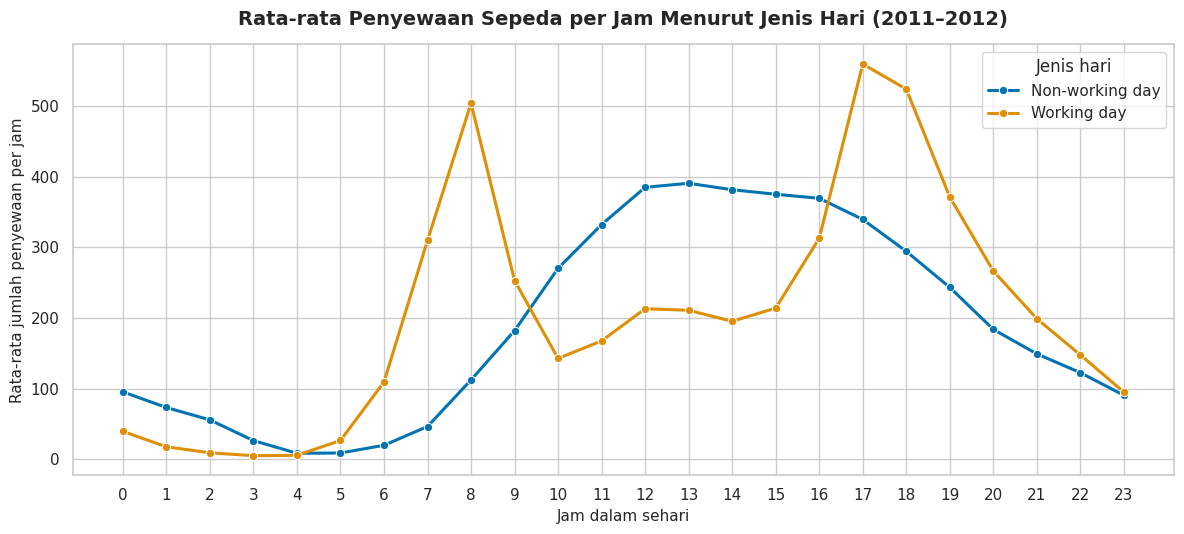

In [12]:
plt.figure(figsize=(12, 5.5))
sns.lineplot(
    data=hourly_profile,
    x="hr", y="avg_rentals", hue="day_type",
    marker="o", linewidth=2.2
)
plt.title("Rata-rata Penyewaan Sepeda per Jam Menurut Jenis Hari (2011–2012)", pad=14, weight="bold")
plt.xlabel("Jam dalam sehari")
plt.ylabel("Rata-rata jumlah penyewaan per jam")
plt.xticks(range(24))
plt.legend(title="Jenis hari", frameon=True)
plt.tight_layout()
plt.show()

**Explanatory insight — Pertanyaan 1:**

Kurva hari kerja memperlihatkan puncak pada pagi dan terutama sore hari, sedangkan hari bukan kerja memiliki pola yang lebih menyebar dan puncak pada sekitar tengah hari. Perbedaan ini dapat menjadi dasar penjadwalan redistribusi armada, tetapi perlu dipahami sebagai pola rata-rata historis pada periode 2011–2012.

### Pertanyaan 2: Bagaimana rata-rata penyewaan harian berbeda menurut musim dan kondisi cuaca?

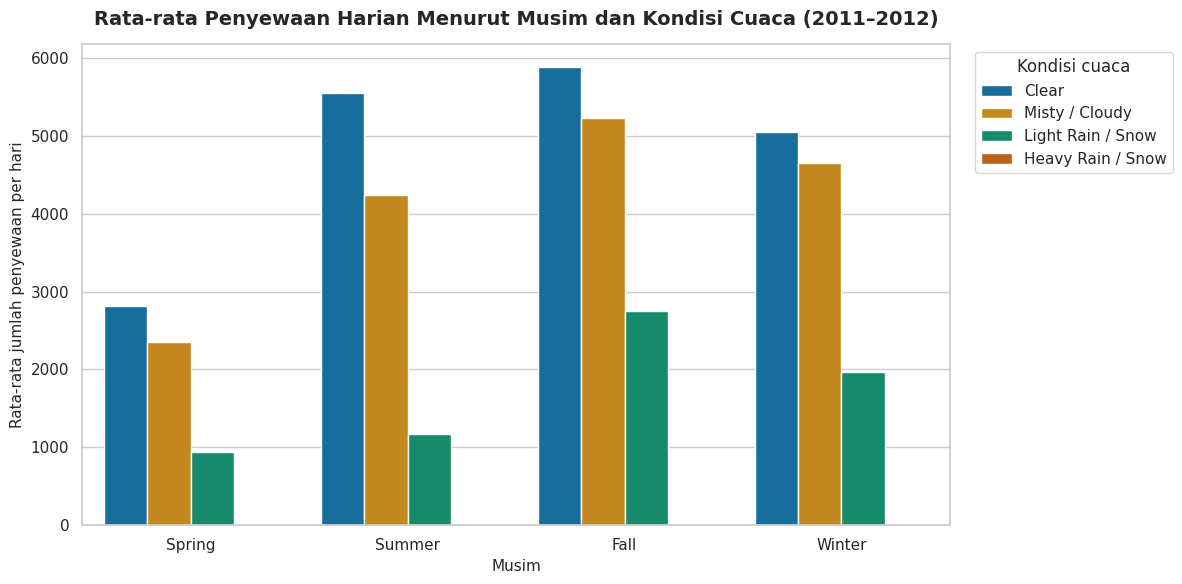

In [13]:
season_order = ["Spring", "Summer", "Fall", "Winter"]
weather_order = ["Clear", "Misty / Cloudy", "Light Rain / Snow", "Heavy Rain / Snow"]

plt.figure(figsize=(12, 6))
sns.barplot(
    data=season_weather,
    x="season_label", y="avg_rentals", hue="weather_label",
    order=season_order, hue_order=weather_order,
    errorbar=None
)
plt.title("Rata-rata Penyewaan Harian Menurut Musim dan Kondisi Cuaca (2011–2012)", pad=14, weight="bold")
plt.xlabel("Musim")
plt.ylabel("Rata-rata jumlah penyewaan per hari")
plt.legend(title="Kondisi cuaca", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Explanatory insight — Pertanyaan 2:**

Grafik membandingkan rata-rata penyewaan harian pada kombinasi musim dan cuaca. Kelompok dengan rata-rata tinggi menunjukkan kondisi yang berasosiasi dengan permintaan lebih besar dalam dataset, sedangkan kelompok dengan rata-rata rendah dapat menjadi perhatian dalam perencanaan kapasitas. Interpretasi perlu mempertimbangkan jumlah hari pada tiap kelompok dan tidak boleh disimpulkan sebagai pengaruh kausal.

## Analisis Lanjutan (Opsional): Binning Tingkat Permintaan

Analisis lanjutan menggunakan teknik **binning** untuk mengelompokkan hari berdasarkan jumlah penyewaan. Batas kategori ditentukan dari sebaran `cnt` pada data harian (tercile/kuantil), bukan dengan algoritma machine learning. Tujuannya adalah menyederhanakan pemantauan tingkat permintaan.

In [14]:
demand_bins = day_clean.copy()
demand_bins["demand_level"] = pd.qcut(
    demand_bins["cnt"],
    q=3,
    labels=["Low demand", "Medium demand", "High demand"]
)

demand_by_season = (
    demand_bins.groupby(["season_label", "demand_level"], observed=False)
    .size()
    .rename("number_of_days")
    .reset_index()
)
demand_by_season["percentage_within_season"] = (
    demand_by_season["number_of_days"] /
    demand_by_season.groupby("season_label")["number_of_days"].transform("sum") * 100
)

display(demand_by_season.round(1))

,season_label,demand_level,number_of_days,percentage_within_season
0,Fall,Low demand,13,6.90
1,Fall,Medium demand,79,42.00
2,Fall,High demand,96,51.10
3,Spring,Low demand,140,77.30
4,Spring,Medium demand,33,18.20
5,Spring,High demand,8,4.40
6,Summer,Low demand,37,20.10
7,Summer,Medium demand,71,38.60
8,Summer,High demand,76,41.30
9,Winter,Low demand,54,30.30


**Insight analisis lanjutan:**

Binning membentuk tiga tingkat permintaan berdasarkan distribusi jumlah penyewaan harian. Proporsi setiap tingkat pada masing-masing musim dapat digunakan sebagai ringkasan untuk perencanaan kapasitas. Batas kuantil bersifat relatif terhadap dataset 2011–2012, sehingga perlu dihitung ulang jika digunakan pada periode atau kota lain.

## Conclusion & Recommendation

### Kesimpulan

1. **Pertanyaan 1 — Pola per jam dan jenis hari:** rata-rata penyewaan pada hari kerja mencapai puncak sekitar pukul **17.00**, sedangkan pada hari bukan kerja mencapai puncak sekitar pukul **13.00**. Perbedaan ini menunjukkan kebutuhan operasional armada yang tidak sama sepanjang hari.
2. **Pertanyaan 2 — Musim dan cuaca:** berdasarkan rata-rata kelompok, kombinasi **Fall–Clear** menunjukkan rata-rata penyewaan harian tertinggi, sedangkan **Spring–Light Rain / Snow** terendah pada data yang tersedia. Jumlah hari per kombinasi berbeda, jadi rata-rata kelompok perlu dibaca bersama ukuran sampelnya.

### Rekomendasi Action Item

1. **Penjadwalan redistribusi:** prioritaskan pemantauan dan redistribusi sepeda menjelang jam sibuk hari kerja (terutama sore hari) dan siapkan ketersediaan lebih merata pada rentang tengah hari saat hari bukan kerja.
2. **Perencanaan musiman:** gunakan pola historis musim dan cuaca untuk menyusun rencana kapasitas; siapkan strategi operasional yang lebih fleksibel pada kondisi cuaca kurang mendukung.
3. **Pemantauan berkelanjutan:** evaluasi kembali pola dengan data terbaru dan pantau data jam yang tidak tercatat agar keputusan tidak bias oleh ketidaklengkapan observasi.

> Rekomendasi ini merupakan implikasi operasional dari pola deskriptif pada dataset Washington, D.C. tahun 2011–2012. Hasil tidak membuktikan bahwa musim atau cuaca menyebabkan perubahan penyewaan.

## Referensi Dataset

Fanaee-T, H., & Gama, J. (2013). *Event labeling combining ensemble detectors and background knowledge*. **Progress in Artificial Intelligence**. https://doi.org/10.1007/s13748-013-0040-3

Deskripsi dataset menyebutkan bahwa data berasal dari Capital Bikeshare, Washington, D.C., dengan agregasi harian dan per jam serta informasi cuaca dan musim.